# Introdução às Redes Neurais e Deep Learning

## O Perceptron Multicamada - Continuação

### Investigando o treinamento de redes neurais: por que redes iguais podem aprender de maneiras diferentes?


#### **Previsão de consumo elétrico com a base de dados PJME_hourly: influência das configurações de treinamento na previsão de carga elétrica**

In [1]:
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense,Input
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

##### **Função para predições**

In [2]:
def predict (model, X_test, y_test,forecast_horizon):
    # Previsões
    y_pred = model.predict(X_test)
    
    # Inverter normalização: Converte osdados de um tensor 3D para um tensor 2D de forma 
    # que o inverse_tranformam() possa inverter a normalização e depois restaura o formato original dos dados. 
    y_test_inv = scaler.inverse_transform(y_test)
    y_pred_inv = scaler.inverse_transform(y_pred)

    # Avaliação por horizonte
    for h in range(forecast_horizon):
        rmse = np.sqrt(mean_squared_error(y_test_inv[:, h], y_pred_inv[:, h]))#Erro quadrático médio
        mae = mean_absolute_error(y_test_inv[:, h], y_pred_inv[:, h])# Erro absoluto médio
        print(f'Horizonte {h+1}h - RMSE: {rmse:.2f} MW')

    # Visualização para 1 exemplo
    plt.figure(figsize=(10, 5))
    plt.plot(range(6), y_test_inv[24], label='Real')
    plt.plot(range(6), y_pred_inv[24], label='Previsto')
    plt.xlabel('Horas à frente')
    plt.ylabel('Carga (MW)')
    plt.title('Previsão das próximas 6 horas')
    plt.legend()
    plt.grid(True)
    plt.show()

##### **Leitura e preparação dos dados**

In [3]:
df = pd.read_csv('Files\\PJME_hourly.csv')
df['Datetime'] = pd.to_datetime(df['Datetime'])

# Agora os elementos da coluna Datetime são do tipo Timestamp
data = df['Datetime'].iloc[0]
print(data)
print('data:',data)
print('ano:',data.year)
print('mês:',data.month)
print('dia:',data.day)
print('hora:',data.hour)
print('type(data.hour:',type(data.hour))

data = df['Datetime'].iloc[1]
print('\n', data)
print('data:',data)
print('ano:',data.year)
print('mês:',data.month)
print('dia:',data.day)
print('hora:',data.hour)

df = df.set_index('Datetime')
df = df.resample('h').mean().ffill()  # Garantir frequência horária e sem valores nulos

2002-12-31 01:00:00
data: 2002-12-31 01:00:00
ano: 2002
mês: 12
dia: 31
hora: 1
type(data.hour: <class 'int'>

 2002-12-31 02:00:00
data: 2002-12-31 02:00:00
ano: 2002
mês: 12
dia: 31
hora: 2


In [4]:
# Normalização dos dados
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df).ravel() # scaled_data é um numpy.ndarray (N,)

# Função para criar janelas
def create_sequences(data, window_size=24, forecast_horizon=6):
    X, y = [], []
    for i in range(len(data) - window_size - forecast_horizon + 1):
        X.append(data[i:i+window_size]) # Cria o *array* de sequências de 24 horas
        y.append(data[i+window_size:i+window_size+forecast_horizon]) # o label(alvo) são as próximas 6 horas. 
    return np.array(X), np.array(y) # X e y são arrays NumPy. 

# Parâmetros
window_size = 24   # últimas 24 horas
forecast_horizon = 6  # prever as próximas 6 horas

X, y = create_sequences(scaled_data, window_size, forecast_horizon)

# Dividir em treino e teste
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

##### **Configuração dos modelos**

In [5]:
def criar_modelo(optimizer='adam',learning_rate=0.001):
    opt=optimizer
    lr=learning_rate
    model = keras.Sequential([
        keras.Input(shape=(24,)),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dense(6,activation='linear')
    ])

    if opt== 'sgd':
        model.compile(optimizer=keras.optimizers.SGD(learning_rate=lr,momentum=0.0), loss='mse', metrics=['mae'])
    else:
        model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),loss='mse', metrics=['mae'])
    return model

##### **Treino do modelo**

In [10]:
# Treinar modelos com e sem Shuffle e adam
keras.utils.set_random_seed(42)
model_sem = criar_modelo()

history_sem = model_sem.fit(X_train, y_train,epochs=150,batch_size=32,validation_split=0.1,shuffle=False,verbose=0)

keras.utils.set_random_seed(42)
model_com = criar_modelo()

history_com = model_com.fit(X_train, y_train,epochs=150,batch_size=32,validation_split=0.1,shuffle=True,verbose=0)

##### **Verificação das predições**

909/909 ━━━━━━━━━━━━━━━━━━━━ 1s 556us/step
Horizonte 1h - RMSE: 481.28 MW
Horizonte 2h - RMSE: 793.40 MW
Horizonte 3h - RMSE: 1125.25 MW
Horizonte 4h - RMSE: 1452.73 MW
Horizonte 5h - RMSE: 1708.57 MW
Horizonte 6h - RMSE: 1911.47 MW


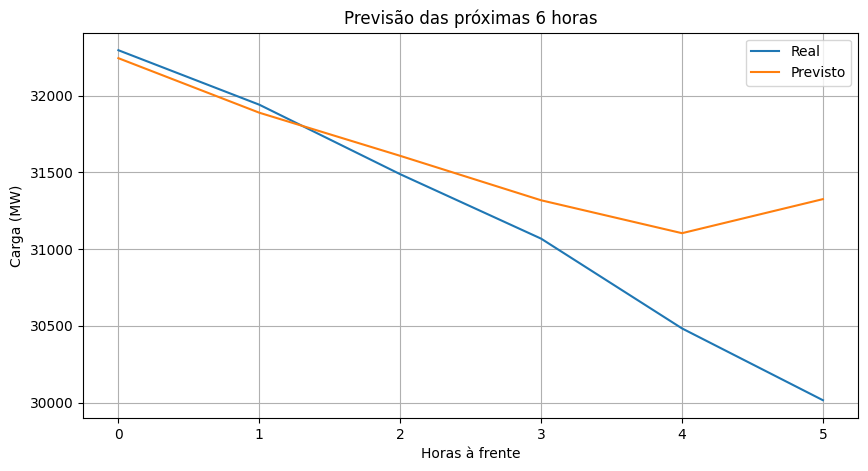

In [11]:
predict(model_sem, X_test, y_test,forecast_horizon)

909/909 ━━━━━━━━━━━━━━━━━━━━ 1s 555us/step
Horizonte 1h - RMSE: 379.72 MW
Horizonte 2h - RMSE: 593.10 MW
Horizonte 3h - RMSE: 809.24 MW
Horizonte 4h - RMSE: 1043.57 MW
Horizonte 5h - RMSE: 1273.41 MW
Horizonte 6h - RMSE: 1477.64 MW


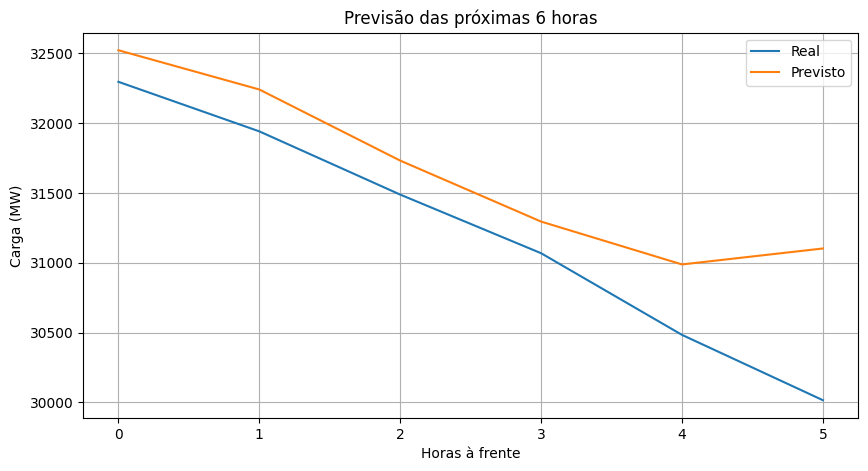

In [12]:
predict(model_com,X_test, y_test,forecast_horizon)

##### **Convergência dos modelos**

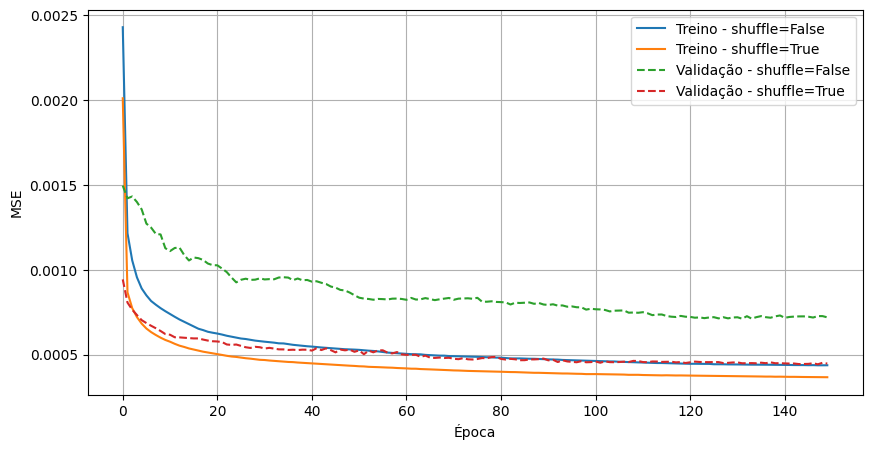

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(history_sem.history['loss'],
         label='Treino - shuffle=False')

plt.plot(history_com.history['loss'],
         label='Treino - shuffle=True')

plt.plot(history_sem.history['val_loss'], '--',
         label='Validação - shuffle=False')

plt.plot(history_com.history['val_loss'], '--',
         label='Validação - shuffle=True')

plt.xlabel('Época')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)
plt.show()

* Analise por que a mesma rede, com os mesmos dados, apresenta diferenças quando  `shuffle=False` é alterado para `shuffle=True`?
* Como se comportam as redes nos conjuntos de treino, validação e generalização?
* Qual o impacto do embaralhamento?
* Os modelos são utilizados para prever as próximas seis horas de carga elétrica. A inspeção visual de uma janela sugere desempenhos discordantes se comparados comos RMSE calculados no conjunto de teste. Como explicar essa observação?


##### **Repetição dos experimentos com SGD puro**

In [6]:
# Treinar modelos com e sem Shuffle e sgd
keras.utils.set_random_seed(42)
model_sem = criar_modelo(optimizer='sgd',learning_rate=0.01)

history_sem = model_sem.fit(X_train, y_train,epochs=500,batch_size=32,validation_split=0.1,shuffle=False,verbose=0)

keras.utils.set_random_seed(42)
model_com = criar_modelo(optimizer='sgd',learning_rate=0.01)

history_com = model_com.fit(X_train, y_train,epochs=500,batch_size=32,validation_split=0.1,shuffle=True,verbose=0)

909/909 ━━━━━━━━━━━━━━━━━━━━ 1s 863us/step
Horizonte 1h - RMSE: 562.02 MW
Horizonte 2h - RMSE: 840.35 MW
Horizonte 3h - RMSE: 1129.85 MW
Horizonte 4h - RMSE: 1383.31 MW
Horizonte 5h - RMSE: 1605.94 MW
Horizonte 6h - RMSE: 1809.77 MW


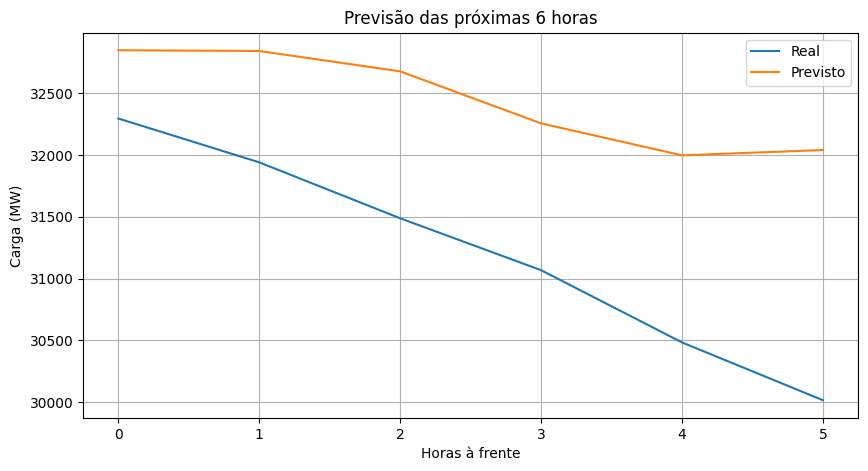

In [7]:
predict(model_sem,X_test, y_test,forecast_horizon)

909/909 ━━━━━━━━━━━━━━━━━━━━ 1s 884us/step
Horizonte 1h - RMSE: 493.63 MW
Horizonte 2h - RMSE: 760.17 MW
Horizonte 3h - RMSE: 1031.01 MW
Horizonte 4h - RMSE: 1301.64 MW
Horizonte 5h - RMSE: 1522.60 MW
Horizonte 6h - RMSE: 1732.92 MW


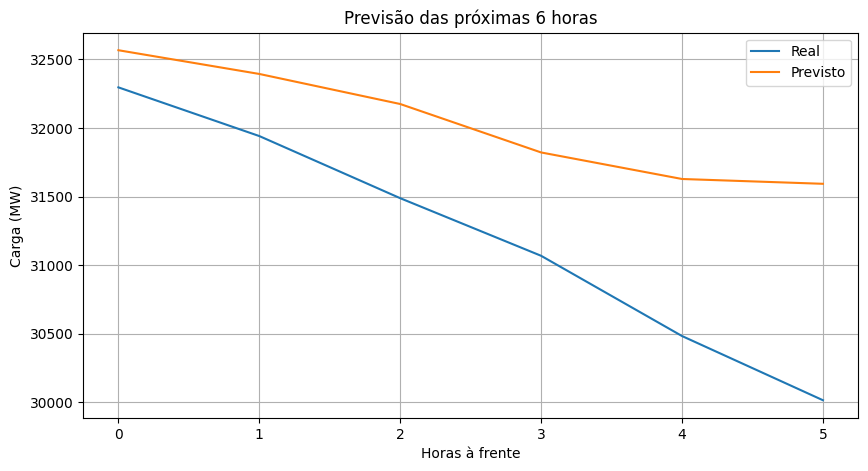

In [8]:
predict(model_com,X_test, y_test,forecast_horizon)

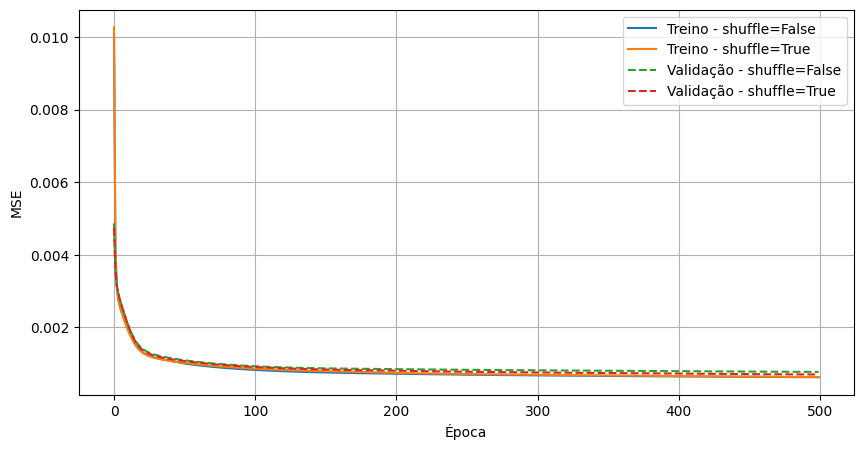

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(history_sem.history['loss'],
         label='Treino - shuffle=False')

plt.plot(history_com.history['loss'],
         label='Treino - shuffle=True')

plt.plot(history_sem.history['val_loss'], '--',
         label='Validação - shuffle=False')

plt.plot(history_com.history['val_loss'], '--',
         label='Validação - shuffle=True')

plt.xlabel('Época')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)
plt.show()

* Analise os resultados comparativamente ao resultados com Adam, considerando os dados de treino, validação e generalização.
* Refaça os experimentos utilizando Adam, *activation*= softmax e *loss*= binary_crossentropy (logloss).  Como são os resultados obtidos em relação aos esperados? Use
  ```python
   model6.compile(optimizer='adam',loss='binary_crossentropy',metrics=[keras.metrics.MeanSquaredError(name='mse'),
                                                                       keras.metrics.RootMeanSquaredError(name='rmse')]) 

e

``` python
plt.plot(history.history['rmse'], label='Treinamento')
plt.plot(history.history['val_rmse'], label='Validação')

plt.xlabel('Época')
plt.ylabel('RMSE (normalizado)')
plt.legend()
plt.grid(True)
plt.show()                                                      